# Esercitazione 1 — Naïve Bayes

In questo notebook vediamo:
1. **GaussianNB** su `load_iris()` (feature continue), con le probabilità a posteriori via `predict_proba()`;
2. **MultinomialNB** e **BernoulliNB** per la classificazione di testo (spam / non spam) con `CountVectorizer`.

**Idea:** il classificatore applica il teorema di Bayes assumendo l'indipendenza condizionale ("naïve") delle feature data la classe:

$$P(C_k \mid x_1,\dots,x_n) \propto P(C_k)\prod_{i=1}^{n} P(x_i \mid C_k)$$

Cambia solo la distribuzione assunta per $P(x_i \mid C_k)$: gaussiana (feature continue), multinomiale (conteggi), Bernoulli (feature binarie).

## 0. Setup e importazioni

In [1]:
# Import delle librerie di base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Moduli di scikit-learn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # seme fisso per la riproducibilità

## Parte A — GaussianNB su Iris

### 1. Caricamento del dataset
Iris: 150 fiori, 4 feature (lunghezza/larghezza di sepalo e petalo), 3 classi (setosa, versicolor, virginica).

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
target_names = iris.target_names
feature_names = iris.feature_names

df = pd.DataFrame(X, columns=feature_names)
df["specie"] = pd.Categorical.from_codes(y, target_names)
display(df.head())
print(df["specie"].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),specie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


specie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### 2. Suddivisione in Training (70%) e Test (30%)

In [3]:
# Split 70% train / 30% test.
# random_state=42 -> risultato riproducibile; stratify=y -> stesse proporzioni di classi in train e test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (105, 4) | Test: (45, 4)


## Feature Scaling con `StandardScaler`

`StandardScaler` trasforma ogni feature in modo che abbia media 0 e deviazione standard 1: $z = (x - \mu)/\sigma$.

**Regola fondamentale:**
1. `fit_transform` sul **training set**: lo scaler *impara* media e deviazione standard dai soli dati di training e li applica.
2. `transform` sul **test set**: si riusano gli stessi $\mu$ e $\sigma$ del training.

Se facessimo `fit` anche sul test (o sull'intero dataset) useremmo informazioni che nella realtà non abbiamo ancora: è il **data leakage**, che rende le stime di performance troppo ottimistiche. Il test set deve simulare dati *mai visti*.


    > **Nota per Naïve Bayes:** GaussianNB stima media e varianza *per classe* di ogni feature, quindi **non richiede** lo scaling (le predizioni non cambiano). Lo applichiamo qui per mantenere la stessa pipeline degli altri notebook, dove invece è indispensabile (KNN e SVM).

In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # fit + transform SOLO sul train
X_test_s = scaler.transform(X_test)        # solo transform sul test (stessi mu e sigma del train)

print("Medie train scalato:", X_train_s.mean(axis=0).round(2))
print("Dev. std train scalato:", X_train_s.std(axis=0).round(2))

Medie train scalato: [ 0. -0. -0. -0.]
Dev. std train scalato: [1. 1. 1. 1.]


### 3. Inizializzazione e addestramento
`var_smoothing` aggiunge una piccola frazione della varianza massima per evitare varianze nulle (stabilità numerica).

In [5]:
gnb = GaussianNB(var_smoothing=1e-9)
gnb.fit(X_train_s, y_train)

print("Probabilità a priori delle classi:", gnb.class_prior_.round(3))
print("Medie per classe (theta_):\n", pd.DataFrame(gnb.theta_, index=target_names, columns=feature_names).round(2))

Probabilità a priori delle classi: [0.333 0.333 0.333]
Medie per classe (theta_):
             sepal length (cm)  sepal width (cm)  petal length (cm)  \
setosa                  -1.03              0.81              -1.29   
versicolor               0.09             -0.71               0.25   
virginica                0.94             -0.10               1.04   

            petal width (cm)  
setosa                 -1.25  
versicolor              0.13  
virginica               1.12  


### 4. Predizione: `predict()` e `predict_proba()`

In [6]:
y_pred = gnb.predict(X_test_s)
y_proba = gnb.predict_proba(X_test_s)   # shape (n_campioni, n_classi); ogni riga somma a 1

# Probabilità a posteriori per i primi 5 campioni di test
proba_df = pd.DataFrame(y_proba[:5], columns=[f"P({c}|x)" for c in target_names]).round(4)
proba_df["classe_predetta"] = target_names[y_pred[:5]]
proba_df["classe_vera"] = target_names[y_test[:5]]
display(proba_df)

,P(setosa|x),P(versicolor|x),P(virginica|x),classe_predetta,classe_vera
0,0.0,0.0000,1.0000,virginica,virginica
1,0.0,0.9955,0.0045,versicolor,versicolor
2,0.0,0.8472,0.1528,versicolor,virginica
3,0.0,0.6680,0.3320,versicolor,versicolor
4,0.0,0.1036,0.8964,virginica,virginica


#### Probabilità a posteriori su un singolo campione di test

P(    setosa | x) = 0.0000
P(versicolor | x) = 0.0000
P( virginica | x) = 1.0000

Predetta: virginica | Vera: virginica


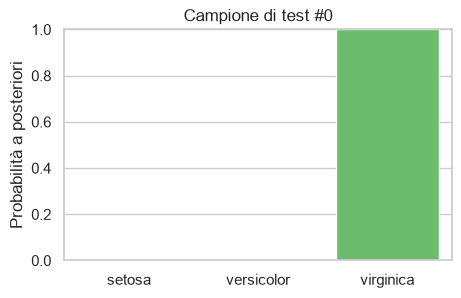

In [7]:
idx = 0
campione = X_test_s[idx].reshape(1, -1)
p = gnb.predict_proba(campione)[0]

for classe, prob in zip(target_names, p):
    print(f"P({classe:>10} | x) = {prob:.4f}")
print(f"\nPredetta: {target_names[gnb.predict(campione)[0]]} | Vera: {target_names[y_test[idx]]}")

plt.figure(figsize=(5, 3))
sns.barplot(x=list(target_names), y=p, hue=list(target_names), legend=False, palette="viridis")
plt.ylabel("Probabilità a posteriori"); plt.ylim(0, 1)
plt.title(f"Campione di test #{idx}")
plt.show()

### 5. Valutazione e matrice di confusione

Accuracy sul test set: 0.9111

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



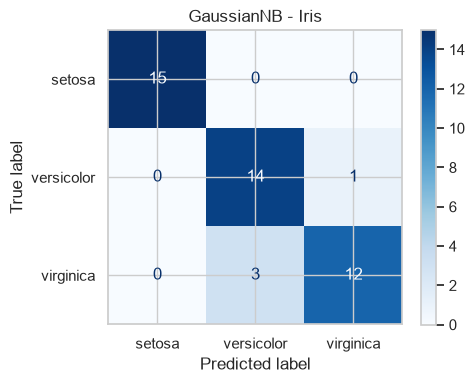

In [8]:
# Valutazione: accuracy, classification report e matrice di confusione
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy sul test set: {acc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=target_names))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=target_names, cmap="Blues", ax=ax)
ax.set_title("GaussianNB - Iris")
plt.tight_layout()
plt.show()

## Parte B — Naïve Bayes per il testo: MultinomialNB vs BernoulliNB

Il testo va trasformato in numeri. `CountVectorizer` costruisce un vocabolario e rappresenta ogni documento come vettore di **conteggi** delle parole (bag-of-words).

| Modello | Feature | Cosa modella |
|---|---|---|
| `MultinomialNB` | conteggi (quante volte compare ogni parola) | frequenza dei termini |
| `BernoulliNB` | binarie (parola presente / assente) | presenza dei termini (penalizza anche le assenze) |

Usiamo un piccolo corpus di esempio (spam = 1, non spam = 0).

In [9]:
testi = [
    # --- SPAM ---
    "vinci subito un premio gratis clicca qui", "offerta imperdibile gratis solo oggi",
    "hai vinto una carta regalo clicca ora", "guadagna soldi facili senza fatica",
    "promozione esclusiva sconto 90% compra ora", "congratulazioni vincitore premio gratis reclama ora",
    "ottieni un prestito veloce senza controlli", "iscriviti gratis e vinci un viaggio",
    "free money click now winner prize", "limited offer buy now cheap pills",
    "claim your free gift card now", "you won a lottery click here to claim",
    # --- NON SPAM (ham) ---
    "ciao ci vediamo domani alla riunione", "ti mando i documenti del progetto in allegato",
    "possiamo spostare la call a giovedì pomeriggio", "grazie per la rapida risposta a presto",
    "ricordati di comprare il latte tornando a casa", "ecco il verbale della riunione di ieri",
    "ci vediamo a cena sabato sera con gli amici", "puoi rivedere la bozza della relazione entro venerdì",
    "meeting tomorrow at ten about the project", "please find the report attached thanks",
    "lunch at noon with the team today", "can you review my code before the release",
]
etichette = np.array([1] * 12 + [0] * 12)   # 1 = spam, 0 = ham
classi_testo = ["ham", "spam"]

X_tr_txt, X_te_txt, y_tr_txt, y_te_txt = train_test_split(
    testi, etichette, test_size=0.3, random_state=RANDOM_STATE, stratify=etichette
)
print("Documenti train:", len(X_tr_txt), "| test:", len(X_te_txt))

Documenti train: 16 | test: 8


### MultinomialNB con conteggi
Il vocabolario si impara **solo sul train** (`fit_transform`), poi si applica al test (`transform`) — stessa logica dello scaler.

In [10]:
# --- MultinomialNB (conteggi) ---
cv_count = CountVectorizer()
Xtr_count = cv_count.fit_transform(X_tr_txt)
Xte_count = cv_count.transform(X_te_txt)
print("Dimensione vocabolario:", len(cv_count.vocabulary_))

mnb = MultinomialNB(alpha=1.0)   # alpha=1 -> smoothing di Laplace (evita probabilità zero per parole mai viste)
mnb.fit(Xtr_count, y_tr_txt)
pred_mnb = mnb.predict(Xte_count)

print(f"\nMultinomialNB accuracy: {accuracy_score(y_te_txt, pred_mnb):.3f}")
print(classification_report(y_te_txt, pred_mnb, target_names=classi_testo, zero_division=0))

Dimensione vocabolario: 90

MultinomialNB accuracy: 1.000
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         4
        spam       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



### BernoulliNB con feature binarie
`CountVectorizer(binary=True)` produce 1/0 (presente/assente) invece dei conteggi.

BernoulliNB accuracy: 0.875
              precision    recall  f1-score   support

         ham       1.00      0.75      0.86         4
        spam       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



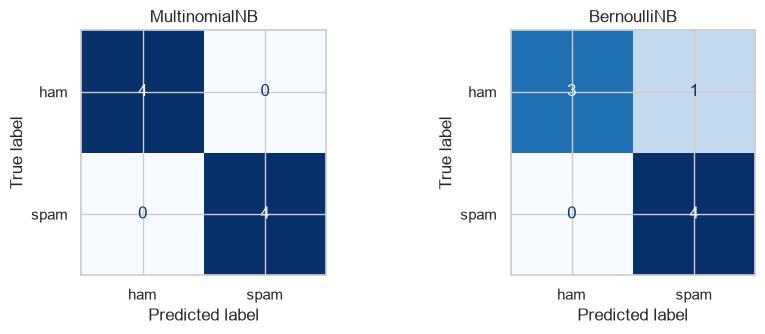

In [11]:
# --- BernoulliNB (feature binarie) ---
cv_bin = CountVectorizer(binary=True)
Xtr_bin = cv_bin.fit_transform(X_tr_txt)
Xte_bin = cv_bin.transform(X_te_txt)

bnb = BernoulliNB(alpha=1.0)
bnb.fit(Xtr_bin, y_tr_txt)
pred_bnb = bnb.predict(Xte_bin)

print(f"BernoulliNB accuracy: {accuracy_score(y_te_txt, pred_bnb):.3f}")
print(classification_report(y_te_txt, pred_bnb, target_names=classi_testo, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, pred, nome in zip(axes, [pred_mnb, pred_bnb], ["MultinomialNB", "BernoulliNB"]):
    ConfusionMatrixDisplay.from_predictions(y_te_txt, pred, display_labels=classi_testo, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout(); plt.show()

### Predizione su nuove frasi (con `predict_proba`)

In [12]:
nuove_frasi = [
    "clicca qui per vincere un premio gratis",
    "ti allego la relazione per la riunione di domani",
    "free prize click now",
]
for nome, vec, modello in [("MultinomialNB", cv_count, mnb), ("BernoulliNB", cv_bin, bnb)]:
    Xn = vec.transform(nuove_frasi)
    pr, pp = modello.predict(Xn), modello.predict_proba(Xn)
    print(f"--- {nome} ---")
    for frase, c, prob in zip(nuove_frasi, pr, pp):
        print(f"{classi_testo[c]:>4}  P(spam)={prob[1]:.3f}  <- '{frase}'")

--- MultinomialNB ---
spam  P(spam)=0.989  <- 'clicca qui per vincere un premio gratis'
 ham  P(spam)=0.014  <- 'ti allego la relazione per la riunione di domani'
spam  P(spam)=0.983  <- 'free prize click now'
--- BernoulliNB ---
spam  P(spam)=0.998  <- 'clicca qui per vincere un premio gratis'
 ham  P(spam)=0.023  <- 'ti allego la relazione per la riunione di domani'
spam  P(spam)=0.996  <- 'free prize click now'


## Riepilogo

- **GaussianNB**: feature continue, assume distribuzioni gaussiane per classe; `predict_proba` restituisce le probabilità a posteriori.
- **MultinomialNB**: ideale per conteggi di parole; **BernoulliNB**: per feature binarie, considera anche l'*assenza* di una parola.
- `alpha` (smoothing di Laplace) evita probabilità nulle per parole non viste.
- Con un corpus così piccolo i risultati sono solo dimostrativi: su dataset reali (es. SMS Spam Collection) servono molti più dati.

**Esercizi proposti:** prova `alpha` diversi (0.1, 0.5, 2), `TfidfVectorizer`, `stop_words`, e cambia `random_state` per vedere la variabilità dello split.